In [22]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import geopandas as gpd
import adjustText
import os

from utils import charger_carte_et_transports, charger_et_nettoyer_dvf, agreger_dvf_par_iris, calculer_zones_tampons, cadrer_carte, etiqueter_stations

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
#Chargement des données via utils
zone_etude, ligne_14, stations_st_ouen = charger_carte_et_transports("93070")
df_logements = charger_et_nettoyer_dvf("93070")
zone_etude_dvf = agreger_dvf_par_iris(df_logements, zone_etude)

In [16]:
#On définit la police de caractères pour les graphiques
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "DejaVu Sans", "Arial"]

#On améliore la qualité des graphiques
%config InlineBackend.figure_format = 'retina'

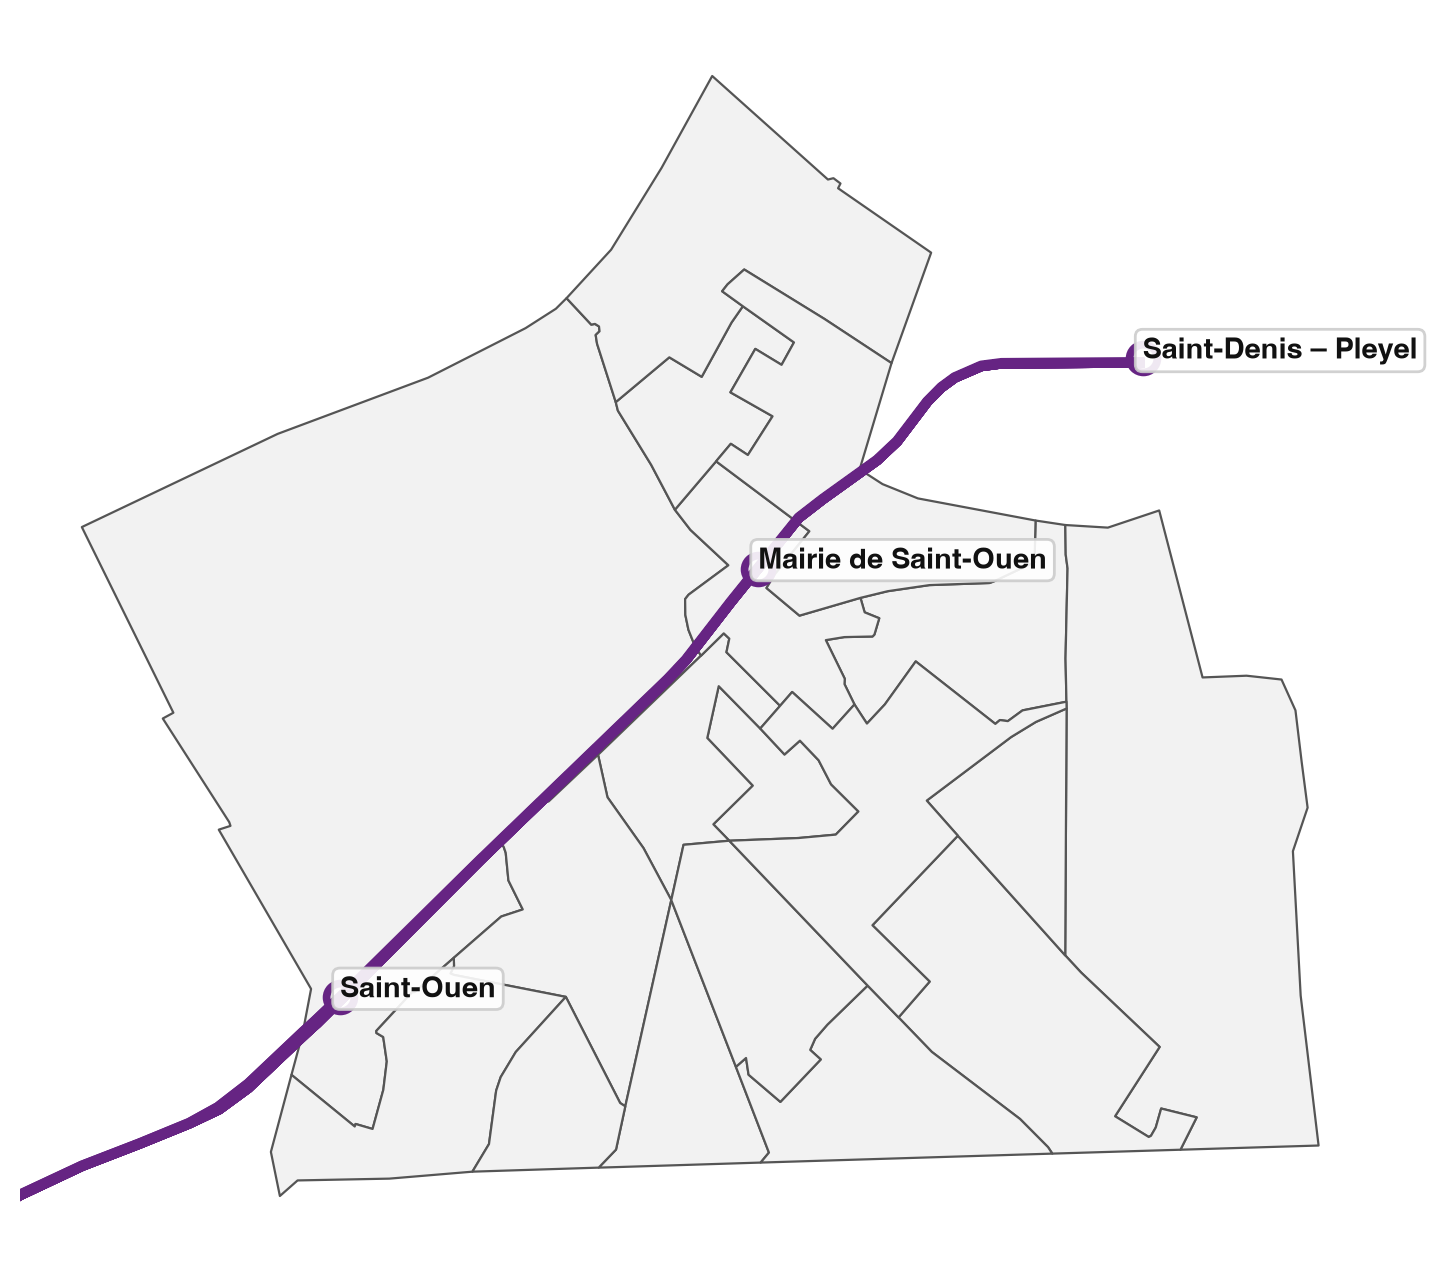

In [23]:
# Visualisation de la zone d'étude et de la ligne 14
fig, ax = plt.subplots(figsize=(10, 8))

zone_etude.plot(
    ax=ax,
    color="#f2f2f2",
    edgecolor="#555555",
    linewidth=0.8,
)
ligne_14.plot(ax=ax, color="#662483", linewidth=3.5, zorder=4)
stations_st_ouen.plot(
    ax=ax,
    color="white",
    edgecolor="#662483",
    linewidth=2.8,
    markersize=100,
    zorder=3,
)

etiqueter_stations(ax, stations_st_ouen, fontsize=10.5)
cadrer_carte(ax, zone_etude)

plt.show()

In [18]:
# 1. Répartition par nature de mutation (effectifs + pourcentages)
df_nature = pd.DataFrame(
    {
        "Effectif": df_logements["nature_mutation"].value_counts(dropna=False),
        "Proportion (%)": (
            df_logements["nature_mutation"].value_counts(
                normalize=True, dropna=False
            )
            * 100
        ).round(1),
    }
)

print("=== Répartition par nature de mutation ===")
print(df_nature)
print("\n" + "=" * 45 + "\n")

# 2. Répartition par type de local (effectifs + pourcentages)
df_type = pd.DataFrame(
    {
        "Effectif": df_logements["type_local"].value_counts(dropna=False),
        "Proportion (%)": (
            df_logements["type_local"].value_counts(
                normalize=True, dropna=False
            )
            * 100
        ).round(1),
    }
)

print("=== Répartition par type de local ===")
print(df_type)

=== Répartition par nature de mutation ===
                                    Effectif  Proportion (%)
nature_mutation                                             
Vente                                   5383            80.8
Vente en l'état futur d'achèvement      1283            19.2


=== Répartition par type de local ===
             Effectif  Proportion (%)
type_local                           
Appartement      6366            95.5
Maison            300             4.5


On constate que sur la période de 2017 à 2025 près de 20% des actes notariés de ventes d'appartements et de maisons enregistrés à Saint-Ouen sont des ventes en l'état futur d'achèvement, i.e. des logements (appartements ou maisons) achetés sur plan, dont près de 95% sont des appartements.

On peut regarder une ville comparable qui a pas eu la 14 pour voir si c'est vrmt le métro qui a eu un effet et pas juste l'évolution naturelle du marché immobilier. Pour détrender on regarde ce qu'aurait été le marché à St Ouen avec un coef régional d'évolution du prix de l'immobilier, et comaprer à la réalité. 

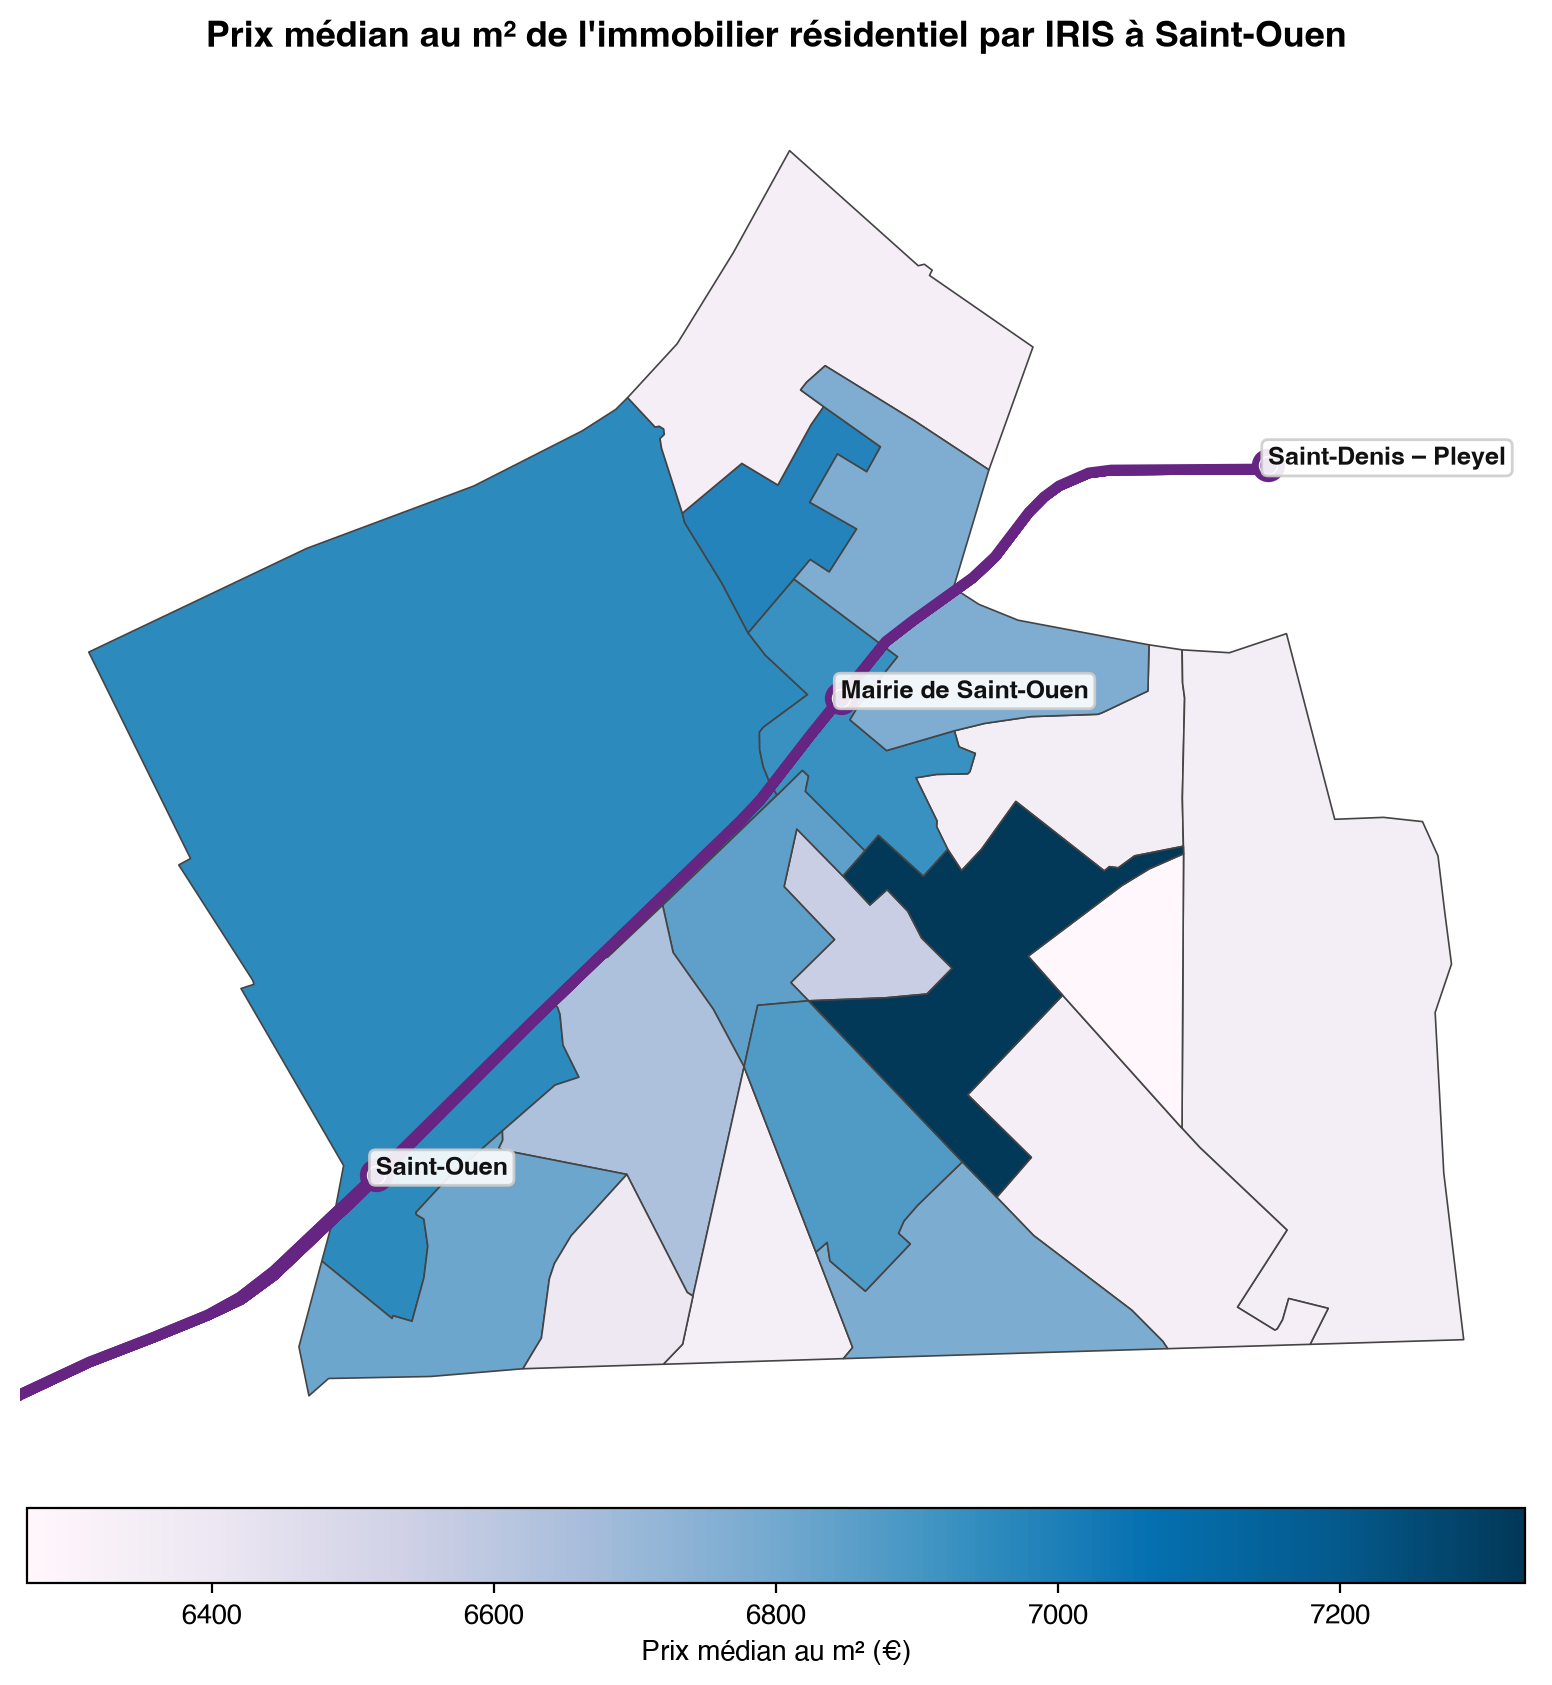

In [24]:
# Carte choroplèthe : prix médian au m² par IRIS
fig, ax = plt.subplots(figsize=(11, 9))

zone_etude_dvf.plot(
    column="prix_m2_median",
    cmap="PuBu",
    linewidth=0.6,
    edgecolor="#444444",
    legend=True,
    legend_kwds={
        "label": "Prix médian au m² (€)",
        "orientation": "horizontal",
        "shrink": 0.7,
        "pad": 0.03,
    },
    missing_kwds={"color": "#e0e0e0", "label": "Ventes insuffisantes"},
    ax=ax,
    zorder=1,
)

# Superposition ligne 14 et stations
ligne_14.plot(ax=ax, color="#662483", linewidth=3.5, zorder=3)
stations_st_ouen.plot(
    ax=ax, color="white", edgecolor="#662483", linewidth=2.5,
    markersize=90, zorder=4,
)
stations_st_ouen.plot(ax=ax, color="#662483", markersize=25, zorder=5)

etiqueter_stations(ax, stations_st_ouen, fontsize=9)
cadrer_carte(ax, zone_etude)

ax.set_title(
    "Prix médian au m² de l'immobilier résidentiel par IRIS à Saint-Ouen",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.tight_layout()
plt.show()

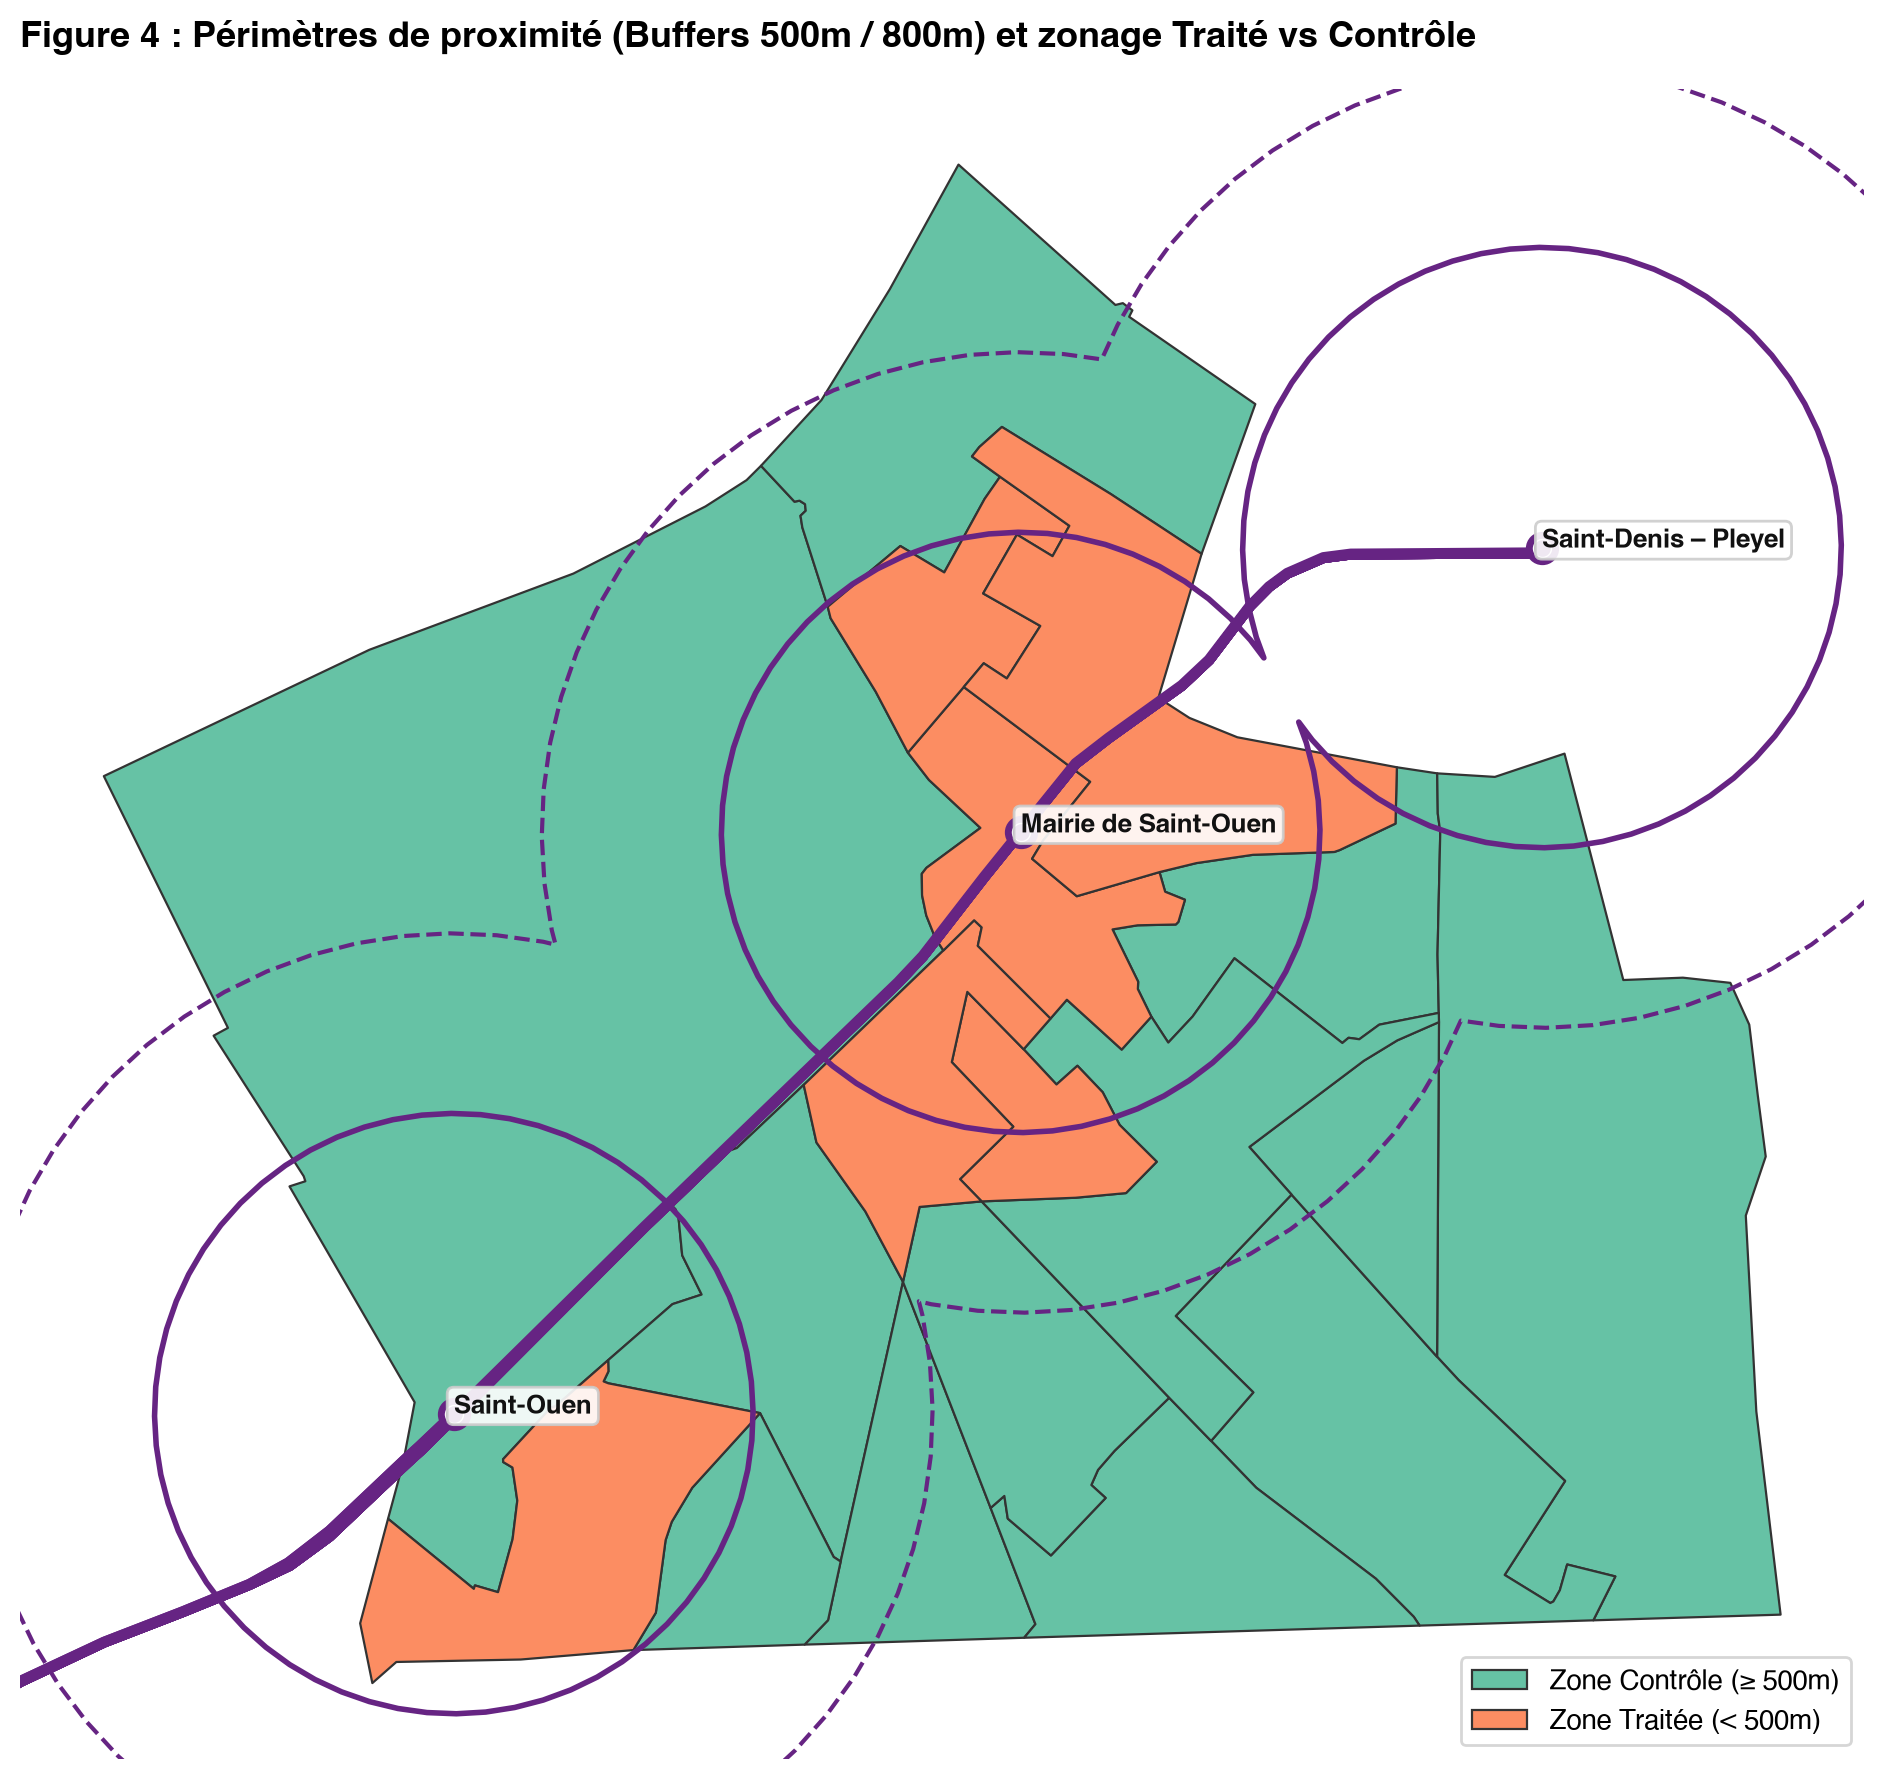

In [32]:
#Méthode DiD pour analyser l'effet de l'arrivée de la ligne 14 (étape finale)

def analyser_evolution_prix_groupes(df_logements, zone_etude_analysis):
  """Croise les ventes DVF avec le zonage Traité vs Contrôle (via jointure spatiale si nécessaire)

  et calcule l'évolution annuelle du prix médian au m².
  """
  col_iris = "code_iris"
  df_temp = df_logements.copy()

  # 1. Si code_iris n'est pas présent dans DVF, on effectue la jointure spatiale via longitude/latitude
  if col_iris not in df_temp.columns:
    df_geo = df_temp.dropna(subset=["longitude", "latitude"]).copy()

    gdf_ventes = gpd.GeoDataFrame(
        df_geo,
        geometry=gpd.points_from_xy(df_geo["longitude"], df_geo["latitude"]),
        crs="EPSG:4326",
    )

    if gdf_ventes.crs != zone_etude_analysis.crs:
      gdf_ventes = gdf_ventes.to_crs(zone_etude_analysis.crs)

    # Assigner le code IRIS et le groupe (Traité vs Contrôle) à chaque transaction
    df_analyse = gpd.sjoin(
        gdf_ventes,
        zone_etude_analysis[[col_iris, "groupe", "dist_station_m", "geometry"]],
        how="inner",
        predicate="within",
    )
  else:
    df_temp[col_iris] = df_temp[col_iris].astype(str)
    zone_copy = zone_etude_analysis.copy()
    zone_copy[col_iris] = zone_copy[col_iris].astype(str)

    df_analyse = df_temp.merge(
        zone_copy[[col_iris, "groupe", "dist_station_m"]],
        on=col_iris,
        how="inner",
    )

  # 2. Tableau pivot du prix médian au m² par année et par groupe
  table_prix = (
      df_analyse.groupby(["annee", "groupe"])["prix_m2"].median().unstack()
  )

  return df_analyse, table_prix



zone_etude, ligne_14, stations_st_ouen = charger_carte_et_transports("93070")
zone_etude_analysis, gdf_buf_500, gdf_buf_800 = calculer_zones_tampons(
    zone_etude, stations_st_ouen, dist_traitee=500, dist_etendue=800
)

# Zonage Traité vs Contrôle
zone_etude_analysis, gdf_buf_500, gdf_buf_800 = calculer_zones_tampons(
    zone_etude, stations_st_ouen, dist_traitee=500, dist_etendue=800
)

# Figure 4 : Périmètres de proximité et zonage
fig, ax = plt.subplots(figsize=(11, 9))

zone_etude_analysis.plot(
    column="groupe",
    categorical=True,
    cmap="Set2",
    linewidth=0.8,
    edgecolor="#333333",
    legend=True,
    legend_kwds={"loc": "lower right", "frameon": True},
    ax=ax,
    zorder=1,
)

# Cercles tampons
gdf_buf_800.plot(
    ax=ax, facecolor="none", edgecolor="#662483",
    linestyle="--", linewidth=1.5, zorder=2,
)
gdf_buf_500.plot(
    ax=ax, facecolor="none", edgecolor="#662483",
    linewidth=2.0, zorder=3,
)

# Ligne 14 et stations
ligne_14.plot(ax=ax, color="#662483", linewidth=3.5, zorder=4)
stations_st_ouen.plot(
    ax=ax, color="white", edgecolor="#662483", linewidth=2.5,
    markersize=90, zorder=5,
)
stations_st_ouen.plot(ax=ax, color="#662483", markersize=25, zorder=6)

etiqueter_stations(ax, stations_st_ouen, fontsize=9.5)
cadrer_carte(ax, zone_etude_analysis)

ax.set_title(
    "Figure 4 : Périmètres de proximité (Buffers 500m / 800m) et zonage Traité vs Contrôle",
    fontsize=13,
    fontweight="bold",
    pad=15,
    loc="left",
)

plt.tight_layout()
plt.show()

=== Prix médian au m² (€) par groupe et par année ===
groupe  Zone Contrôle (≥ 500m)  Zone Traitée (< 500m)
annee                                                
2021                    6773.0                 6965.0
2022                    6970.0                 7019.0
2024                    6360.0                 6385.0
2025                    6466.0                 6451.0


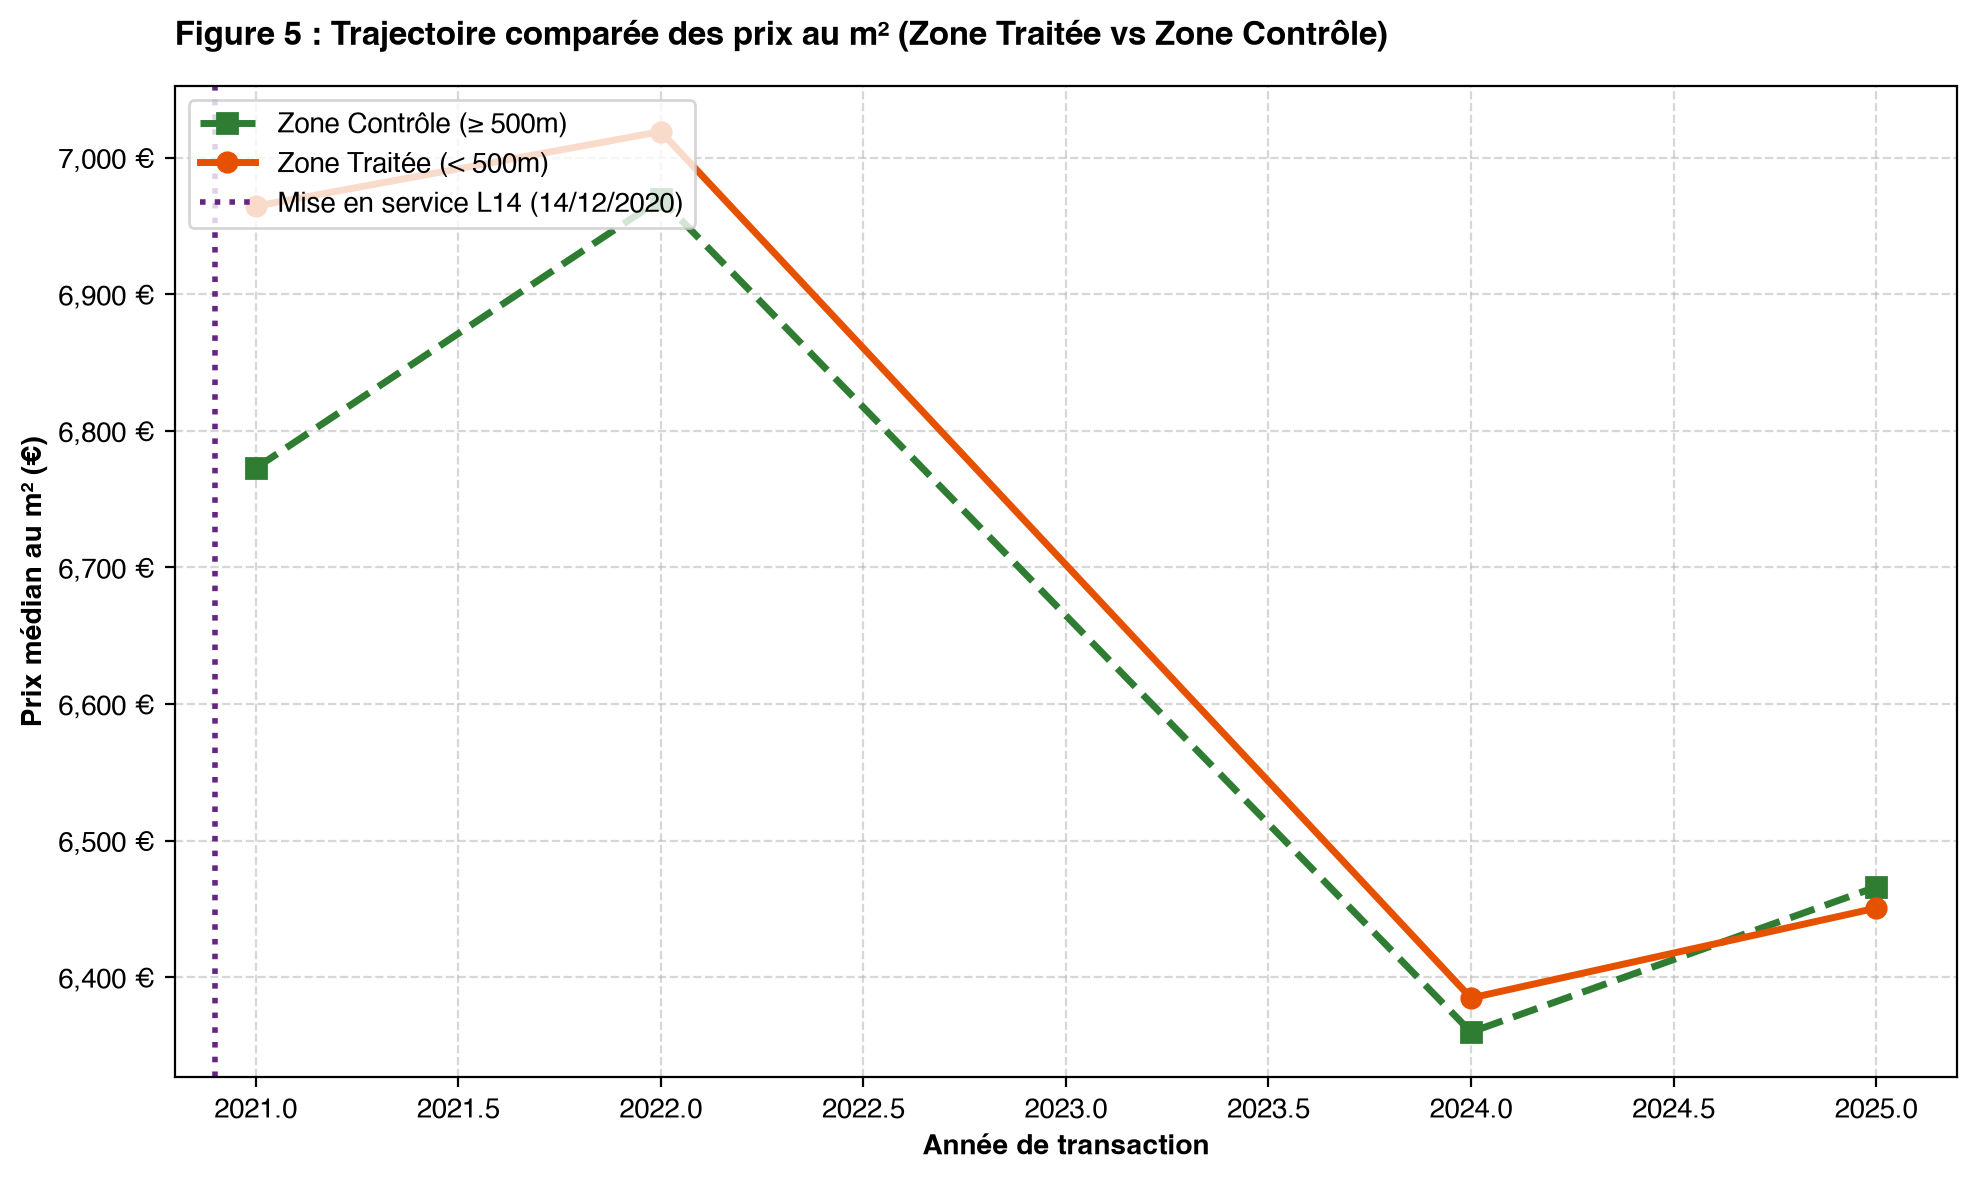

In [33]:
# 1. Calcul des prix médians par année et par zone
df_analyse, table_prix = analyser_evolution_prix_groupes(
    df_logements, zone_etude_analysis
)

# Affichage du tableau récapitulatif
print("=== Prix médian au m² (€) par groupe et par année ===")
print(table_prix.round(0))

# 2. Tracé des trajectoires temporelles
fig, ax = plt.subplots(figsize=(10, 6))

couleurs = {
    "Zone Traitée (< 500m)": "#e65100",
    "Zone Contrôle (≥ 500m)": "#2e7d32",
}
styles = {"Zone Traitée (< 500m)": "o-", "Zone Contrôle (≥ 500m)": "s--"}

for col in table_prix.columns:
    ax.plot(
        table_prix.index,
        table_prix[col],
        styles.get(col, "o-"),
        color=couleurs.get(col, "#333333"),
        linewidth=2.5,
        markersize=7,
        label=col,
    )

# Repère temporel : Inauguration Ligne 14 (Décembre 2020)
ax.axvline(
    x=2020.9,
    color="#662483",
    linestyle=":",
    linewidth=2,
    label="Mise en service L14 (14/12/2020)",
)

# Habillage et légendes
ax.set_title(
    "Figure 5 : Trajectoire comparée des prix au m² (Zone Traitée vs Zone Contrôle)",
    fontsize=12,
    fontweight="bold",
    pad=15,
    loc="left",
)
ax.set_xlabel("Année de transaction", fontsize=10, fontweight="bold")
ax.set_ylabel("Prix médian au m² (€)", fontsize=10, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")

# Formatage de l'axe des ordonnées en euros (€)
ax.yaxis.set_major_formatter("{x:,.0f} €")

plt.tight_layout()
plt.show()

In [34]:
print(df_logements["annee"].value_counts().sort_index())

annee
2017     817
2018     710
2019     681
2020     266
2021     986
2022    1862
2024     591
2025     753
Name: count, dtype: int64
